# Step 8: SHAP Explainability

In [1]:
# Install SHAP into the active notebook environment

import sys
!{sys.executable} -m pip install shap

In [2]:
import sys
from pathlib import Path

# Add src to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

from explainability.shap_analysis import SHAPAnalyzer

# Define paths
model_path = project_root / "models" / "weighted_soft_voting_ensemble.joblib"
validation_data_path = project_root / "data" / "processed" / "splits"
results_path = project_root / "results" / "shap"

print(" Paths initialized:")
print(f"Model: {model_path}")
print(f"Data: {validation_data_path}")
print(f"Results: {results_path}")

# Initialize analyzer
analyzer = SHAPAnalyzer(
    model_path=model_path,
    validation_data_path=validation_data_path,
    results_path=results_path
)

print("\n Analyzer initialized successfully!")

 Paths initialized:
Model: c:\Users\Jiya\Documents\Malicious URL Detection\models\weighted_soft_voting_ensemble.joblib
Data: c:\Users\Jiya\Documents\Malicious URL Detection\data\processed\splits
Results: c:\Users\Jiya\Documents\Malicious URL Detection\results\shap

 Analyzer initialized successfully!


In [3]:
from pathlib import Path
import joblib

project_root = Path.cwd().parent

# Load model
model = joblib.load(project_root / "models/weighted_soft_voting_ensemble.joblib")

# Get Random Forest pipeline
rf_pipeline = model.estimators_[1]

# Print all step names
print("Pipeline steps:")
print(rf_pipeline.named_steps.keys())

Pipeline steps:
dict_keys(['imputer', 'model'])


In [ ]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

project_root = Path.cwd().parent

# Load your existing data
X_val = pd.read_csv(project_root / "data/processed/splits/X_validation.csv")

# Load your existing trained model
model = joblib.load(project_root / "models/weighted_soft_voting_ensemble.joblib")

# Get Random Forest from ensemble
rf_pipeline = model.estimators_[1]
rf_model = rf_pipeline.named_steps['model']  # Corrected step name

# SHAP analysis
X_sample = X_val.iloc[:300].copy()
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_sample, check_additivity=False)

# Plot & save
shap_vals = shap_values[1]
importance = np.abs(shap_vals).mean(axis=0)
indices = np.argsort(importance)[::-1][:20]

plt.figure(figsize=(12, 8))
plt.barh(range(len(indices)), importance[indices])
plt.yticks(range(len(indices)), [X_val.columns[i] for i in indices])
plt.xlabel("Mean |SHAP value|")
plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.savefig(project_root / "results/shap/shap_summary_plot.png", dpi=300)
plt.show()

print("✅ SHAP analysis complete!")

Loading data and model...
Explaining 500 samples...

Initializing KernelExplainer...
Generating SHAP values (15-25 min)...



  0%|          | 0/500 [00:00<?, ?it/s]


✅ SHAP values generated!


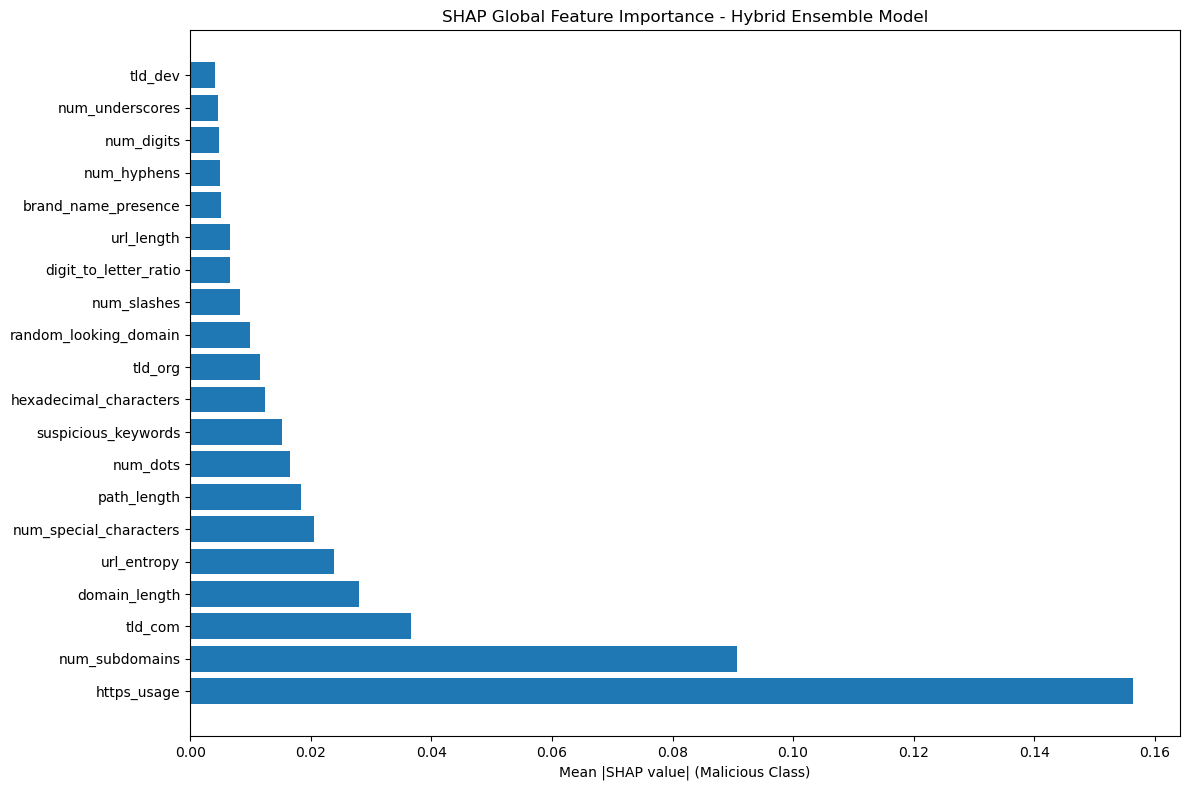


✅ SHAP Analysis Complete!
Results saved to: results/shap/

Top 15 Features:
                    Feature  SHAP_Importance
19              https_usage         0.156376
15           num_subdomains         0.090726
139                 tld_com         0.036691
14            domain_length         0.028005
13              url_entropy         0.023889
5    num_special_characters         0.020517
8               path_length         0.018439
1                  num_dots         0.016505
23      suspicious_keywords         0.015179
22   hexadecimal_characters         0.012449
369                 tld_org         0.011596
26    random_looking_domain         0.009892
2               num_slashes         0.008253
7     digit_to_letter_ratio         0.006622
0                url_length         0.006529


In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

project_root = Path.cwd().parent

print("Loading data and model...")

# Load validation data
X_val = pd.read_csv(project_root / "data/processed/splits/X_validation.csv")
y_val = pd.read_csv(project_root / "data/processed/splits/y_validation.csv").iloc[:, 0]

# Load your HYBRID ensemble model
ensemble_model = joblib.load(project_root / "models/weighted_soft_voting_ensemble.joblib")

# Use smaller sample for speed
X_sample = X_val.iloc[:500].copy()
print(f"Explaining {len(X_sample)} samples...")

# Background data
X_background = X_val.iloc[:100].copy()

print("\nInitializing KernelExplainer...")
explainer = shap.KernelExplainer(
    model=ensemble_model.predict_proba,
    data=X_background
)

print("Generating SHAP values (15-25 min)...\n")
shap_values = explainer.shap_values(X_sample)

print("\n✅ SHAP values generated!")

# Extract SHAP for malicious class (class 1)
shap_vals_malicious = shap_values[:, :, 1]

# Feature importance
importance = np.abs(shap_vals_malicious).mean(axis=0)
indices = np.argsort(importance)[::-1][:20]

# Plot
plt.figure(figsize=(12, 8))
plt.barh(range(len(indices)), importance[indices])
plt.yticks(range(len(indices)), [X_val.columns[i] for i in indices])
plt.xlabel("Mean |SHAP value| (Malicious Class)")
plt.title("SHAP Global Feature Importance - Hybrid Ensemble Model")
plt.tight_layout()
plt.savefig(project_root / "results/shap/shap_summary_ensemble.png", dpi=300, bbox_inches='tight')
plt.show()

# Save importance to CSV
importance_df = pd.DataFrame({
    'Feature': X_val.columns,
    'SHAP_Importance': importance
}).sort_values('SHAP_Importance', ascending=False)

importance_df.to_csv(project_root / "results/shap/feature_importance_ensemble.csv", index=False)

print("\n✅ SHAP Analysis Complete!")
print("Results saved to: results/shap/")
print("\nTop 15 Features:")
print(importance_df.head(15))